# Label Horizon Experiment with LightGBM

The goal of this small project is to test the main idea from the **Label Horizon Paradox** paper using a classical machine-learning model.

The inference goal is always the same: predict the return at horizon `h=10`.

We compare:

- training directly on the final target `h=10`;
- training on each earlier horizon separately;
- using Optuna to learn a mixture of training horizons.

LightGBM cannot be differentiated through like a neural network. Therefore, the inner model is LightGBM and the outer bilevel optimizer is Optuna/TPE.

## 0. Imports

In [3]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 23.1 MB/s eta 0:00:00


In [4]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

### Main settings

In [5]:
random_seed = 42

number_of_dates = 240
number_of_assets = 35
number_of_features = 24

n_horizons = 10
target_horizon = 10
#leave a ten-date gap between  training/validation and test
purge_gap = target_horizon

np.random.seed(random_seed)

## 1. Create the data

To make the notebook runnable without external data, we create a small synthetic stock panel.

- Information is gradually reflected in returns.
- The useful signal eventually saturates.
- Noise continues accumulating at longer horizons.

This gives us a setting where an intermediate label can be cleaner than the final label, even though evaluation is still performed on `h=10`.

In [6]:
def make_synthetic_data(seed=random_seed):
    rng = np.random.default_rng(seed)

    number_of_rows = number_of_dates * number_of_assets
    dates = np.repeat(np.arange(number_of_dates), number_of_assets)
    #(0,0),(0,1)... (239,34) --- (t,i) = (date, stock)
    assets = np.tile(np.arange(number_of_assets), number_of_dates)

    # ------------------------------------------------------------
    # Features
    # ------------------------------------------------------------

    #Initial features
    X = rng.normal(size=(number_of_rows, number_of_features)) #8400x24 ~N(0,1)
    # three fixed characteristics foe each asset
    asset_style = rng.normal(size=(number_of_assets, 3))
    # feature = temp rnd component + persistent asse component
    X[:, :3] += 0.35 * asset_style[assets]

    regime = 0.75 + 0.25 * np.sin(2 * np.pi * dates / 90) #cycle every 90 days

    #True relationship bewteen features and future returns --- features 6--23
    # are just noise
    signal = regime * (
        0.85 * X[:, 0]
        - 0.65 * X[:, 1]
        + 0.45 * X[:, 2] * X[:, 3]
        + 0.35 * np.sin(X[:, 4])
        + 0.20 * X[:, 5] ** 2
    )

    signal = (signal - signal.mean()) / signal.std()

    # ------------------------------------------------------------
    # Returns at horizons h=1,...,10
    # Now we determine how much signal has been realized at each horizon
    # ------------------------------------------------------------

    horizons = np.arange(1, n_horizons + 1)

    signal_realization = 1 - np.exp(-horizons / 1.5) # exponential decay / diffusion
    noise_scale = np.linspace(0.45, 0.95, n_horizons) #linear noise

    noise_increments = (
        rng.normal(size=(number_of_rows, n_horizons))
        * noise_scale
    )

    cumulative_noise = np.cumsum(noise_increments, axis=1)

    common_increments = rng.normal(
        scale=0.25,
        size=(number_of_dates, n_horizons),
    )

    common_noise = np.cumsum(common_increments, axis=1)[dates]

    # r = a(h)s + e_1(asset noise) + e_2(merket wide noise)
    returns = (
        signal[:, None] * signal_realization[None, :]
        + cumulative_noise
        + common_noise
    )

    # ------------------------------------------------------------
    # DataFrame
    # ------------------------------------------------------------

    data = pd.DataFrame(
        X,
        columns=[f"x{i}" for i in range(number_of_features)],
    )

    data["date"] = dates
    data["asset"] = assets

    for h in horizons:
        # data[f"return_h{h}"] = returns[:, h - 1]

        # # Cross-sectional rank standardization for training labels
        # data[f"target_h{h}"] = data.groupby("date")[f"return_h{h}"].transform(
        #     lambda values: (values.rank(pct=True) - 0.5) * np.sqrt(12)
        # )
        return_column = f"return_h{h}"
        target_column = f"target_h{h}"

        data[return_column] = returns[:, h - 1]

        daily_mean = data.groupby("date")[return_column].transform("mean")
        daily_std = data.groupby("date")[return_column].transform(
            lambda values: values.std(ddof=0)
        )
        #Cross-sectional standardization for training labels
        data[target_column] = (
            data[return_column] - daily_mean
        ) / daily_std.replace(0, np.nan)

        data[target_column] = data[target_column].fillna(0.0)

    return data, signal_realization, noise_scale

### Generate and inspect the dataset

In [7]:
data, signal_realization, noise_scale = make_synthetic_data()

feature_columns = [f"x{i}" for i in range(number_of_features)]
target_columns = [f"target_h{h}" for h in range(1, n_horizons + 1)]

print("Shape:", data.shape)
print("Number of dates:", data["date"].nunique())
print("Number of assets:", data["asset"].nunique())

Shape: (8400, 46)
Number of dates: 240
Number of assets: 35


In [8]:
columns_show = [
    "date",
    "asset",
    "return_h1",
    "return_h3",
    "return_h10",
]

data[columns_show].head()

,date,asset,return_h1,return_h3,return_h10
0,0,0,0.262070,-0.634271,-3.096413
1,0,1,-0.260978,-0.396214,-2.335146
2,0,2,-0.130440,1.852829,-2.630231
3,0,3,-0.872978,0.131996,0.607085
4,0,4,-0.502093,0.218543,2.711091


### Signal realization and noise accumulation

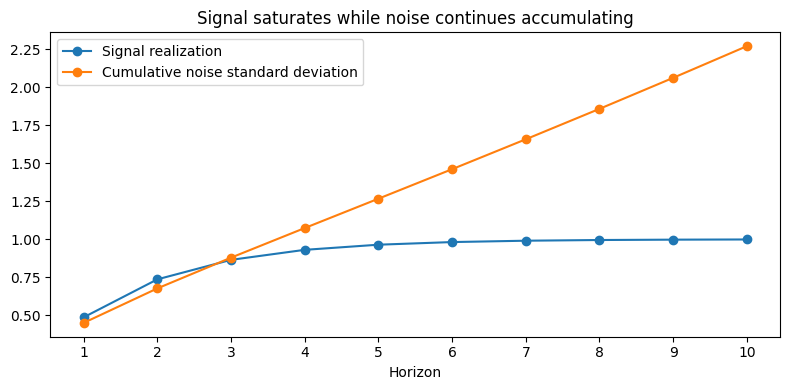

In [9]:
horizons = np.arange(1, n_horizons + 1)
cumulative_noise_std = np.sqrt(np.cumsum(noise_scale ** 2))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    horizons,
    signal_realization,
    marker="o",
    label="Signal realization",
)

ax.plot(
    horizons,
    cumulative_noise_std,
    marker="o",
    label="Cumulative noise standard deviation",
)

ax.set_title("Signal saturates while noise continues accumulating")
ax.set_xlabel("Horizon")
ax.set_xticks(horizons)
ax.legend()

plt.tight_layout()
plt.show()

## 2. Train, validation and test split

We split chronologically and leave a gap equal to the maximum prediction horizon.

- **Train:** fit each candidate model.
- **Validation:** choose the training horizon or horizon mixture.
- **Test:** compare the final methods once, after selection is complete.

In [10]:
train_end = int(number_of_dates * 0.60)
validation_start = train_end + purge_gap

validation_end = int(number_of_dates * 0.80)
test_start = validation_end + purge_gap

train_mask = data["date"] < train_end

validation_mask = (
    (data["date"] >= validation_start)
    & (data["date"] < validation_end)
)

test_mask = data["date"] >= test_start

In [11]:
split_summary = pd.DataFrame(
    {
        "First date": [0, validation_start, test_start],
        "Last date": [train_end - 1, validation_end - 1, number_of_dates - 1],
        "Rows": [
            train_mask.sum(),
            validation_mask.sum(),
            test_mask.sum(),
        ],
    },
    index=["Train", "Validation", "Test"],
)

split_summary

,First date,Last date,Rows
Train,0,143,5040
Validation,154,191,1330
Test,202,239,1330


## 3. Validation metric and LightGBM model

We use mean daily Spearman correlation, which is the cross-sectional Rank IC.

In [12]:
def mean_daily_ic(y_true, y_pred, dates):
    results = pd.DataFrame(
        {
            "date": dates,
            "y_true": y_true,
            "y_pred": y_pred,
        }
    )

    daily_ic = []

    for _, day in results.groupby("date"):
        score = pearsonr(
            day["y_true"],
            day["y_pred"],
        ).statistic

        if np.isfinite(score):
            daily_ic.append(score)

    return float(np.mean(daily_ic))


def mean_daily_rank_ic(y_true, y_pred, dates):
    results = pd.DataFrame(
        {
            "date": dates,
            "y_true": y_true,
            "y_pred": y_pred,
        }
    )

    daily_ic = []

    for _, day in results.groupby("date"):
        score = spearmanr(
            day["y_true"],
            day["y_pred"],
        ).statistic

        if np.isfinite(score):
            daily_ic.append(score)

    return float(np.mean(daily_ic))

In [13]:
def make_model(seed=random_seed):
    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=220,
        learning_rate=0.04,
        num_leaves=23,
        min_child_samples=25,
        subsample=0.85,
        colsample_bytree=0.80,
        reg_lambda=1.0,
        verbosity=-1,
        random_state=seed,
        n_jobs=2,
    )

    return model

### Validation function

This is the main bilevel function:

1. LightGBM is trained on a weighted combination of horizon labels.
2. The fitted model is evaluated on the fixed final target `return_h10`.
3. Optuna will later choose the weights that maximize this validation score.

In [14]:
def validation_scores(weights, seed=random_seed):
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()

    all_targets = data[target_columns].to_numpy()
    training_target = all_targets @ weights

    model = make_model(seed)

    model.fit(
        data.loc[train_mask, feature_columns],
        training_target[train_mask],
    )
    # Applied in validation set
    predictions = model.predict(
        data.loc[validation_mask, feature_columns]
    )
    # as per paper validae on last horizon (10th)
    y_true = data.loc[validation_mask, "return_h10"]
    dates = data.loc[validation_mask, "date"]

    pearson_ic = mean_daily_ic(
        y_true,
        predictions,
        dates,
    )

    rank_ic = mean_daily_rank_ic(
        y_true,
        predictions,
        dates,
    )

    return pearson_ic, rank_ic


def validate_weights(weights, seed=random_seed):
    # Convenience wrapper when only Rank IC is required.
    _, rank_ic = validation_scores(weights, seed)
    return rank_ic

## 4. Baseline: train directly on the final horizon

In [15]:
direct_weights = np.zeros(n_horizons)
direct_weights[-1] = 1

direct_validation_ic, direct_validation_rank_ic = validation_scores(
    direct_weights
)

print(f"Direct h=10 validation IC: {direct_validation_ic:.4f}")
print(f"Direct h=10 validation Rank IC: {direct_validation_rank_ic:.4f}")

Direct h=10 validation IC: 0.2360
Direct h=10 validation Rank IC: 0.2374


## 5. Try every fixed training horizon

The inference target remains `h=10`. We only change the label used to train LightGBM.

In [24]:
horizon_results = []

for h in range(1, n_horizons + 1):
    weights = np.zeros(n_horizons)
    weights[h - 1] = 1

    pearson_ic, rank_ic = validation_scores(weights)

    horizon_results.append(
        {
            "Training horizon": h,
            "Validation IC (Pearson)": pearson_ic,
            "Validation Rank IC (Spearman)": rank_ic,
        }
    )

horizon_results = pd.DataFrame(horizon_results)
horizon_results

,Training horizon,Validation IC (Pearson),Validation Rank IC (Spearman)
0,1,0.272071,0.262074
1,2,0.279055,0.270986
2,3,0.273807,0.264846
3,4,0.280241,0.273780
4,5,0.269402,0.257121
5,6,0.267518,0.263320
6,7,0.266398,0.266910
7,8,0.252174,0.238899
8,9,0.241092,0.231549
9,10,0.235957,0.237447


In [25]:
best_fixed_horizon_rank = int(
    horizon_results.loc[
        horizon_results["Validation Rank IC (Spearman)"].idxmax(),
        "Training horizon",
    ]
)

best_fixed_horizon = int(
    horizon_results.loc[
        horizon_results["Validation IC (Pearson)"].idxmax(),
        "Training horizon",
    ]
)

best_fixed_rank_ic = horizon_results["Validation Rank IC (Spearman)"].max()
best_fixed_pearson_ic = horizon_results["Validation IC (Pearson)"].max()

print("Best fixed horizon by Rank IC:", best_fixed_horizon_rank)
print(f"Best validation Rank IC: {best_fixed_rank_ic:.4f}")
print("Best fixed horizon by Pearson IC:", best_fixed_horizon)
print(f"Best validation Pearson IC: {best_fixed_pearson_ic:.4f}")

Best fixed horizon by Rank IC: 4
Best validation Rank IC: 0.2738
Best fixed horizon by Pearson IC: 4
Best validation Pearson IC: 0.2802


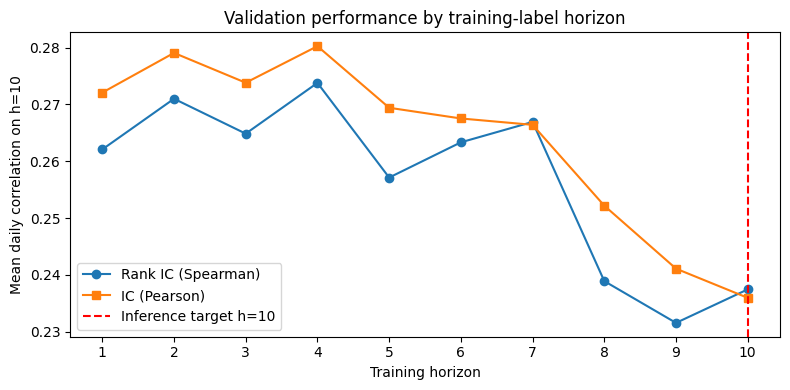

In [26]:
plt.figure(figsize=(8, 4))

plt.plot(
    horizon_results["Training horizon"],
    horizon_results["Validation Rank IC (Spearman)"],
    marker="o",
    label="Rank IC (Spearman)",
)

plt.plot(
    horizon_results["Training horizon"],
    horizon_results["Validation IC (Pearson)"],
    marker="s",
    label="IC (Pearson)",
)

plt.axvline(
    target_horizon,
    color="red",
    linestyle="--",
    label="Inference target h=10",
)

plt.title("Validation performance by training-label horizon")
plt.xlabel("Training horizon")
plt.ylabel("Mean daily correlation on h=10")
plt.xticks(horizons)
plt.legend()

plt.tight_layout()
plt.show()

## 6. Bilevel optimization with Optuna

Instead of selecting only one horizon, we allow the training target to be a mixture of nearby horizons.

The mixture is controlled by:

- `center`: the main training horizon;
- `width`: how much weight is given to neighbouring horizons.

For every Optuna trial:

1. Optuna proposes `center` and `width`.
2. We construct the horizon weights.
3. LightGBM is fitted on the weighted training target.
4. The outer objective balances validation Pearson IC on `h=10` with a moderate entropy reward.

The entropy term discourages the horizon weights from collapsing too aggressively onto one or two horizons. We use one fixed value, `gamma = 0.005`.

In [27]:
def make_horizon_weights(center, width):
  #Use gaussian-shaped weighting
    weights = np.exp(
        -0.5 * ((horizons - center) / width) ** 2
    )

    weights = weights / weights.sum()

    return weights

# We could always ask optuna to optimize 10 independet values, but that would
# create a 10dim out opt. problem and every optuna trial would require a new
# LightGBM, so we ould require many trials.

# With width and center we only search 2-dim.
# Disadvatange: only permits a smooth, single-peaked distribution.

In [28]:
entropy_gamma = 0.005


def normalized_entropy(weights):
    entropy = -np.sum(
        weights * np.log(weights + 1e-12)
    )

    return entropy / np.log(n_horizons)


def objective(trial):
    center = trial.suggest_float(
        "center",
        1,
        n_horizons,
    )

    width = trial.suggest_float(
        "width",
        0.20,
        3.00,
        log=True,
    )

    # Candidate distribution over the ten training horizons.
    weights = make_horizon_weights(center, width)

    #I can use pearson, or spearman here, since no derivative are required.
    pearson_ic, _ = validation_scores(weights) #Outer optimization
    entropy = normalized_entropy(weights)

    # Maximize validation Pearson IC while rewarding smoother weights.
    score = pearson_ic + entropy_gamma * entropy

    return score

In [29]:
sampler = optuna.samplers.TPESampler(
    seed=random_seed,
    n_startup_trials=8,
    multivariate=True,
)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
)

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=False,
)

### Best horizon mixture

In [30]:
best_center = study.best_params["center"]
best_width = study.best_params["width"]

bilevel_weights = make_horizon_weights(
    best_center,
    best_width,
)

best_validation_ic, best_validation_rank_ic = validation_scores(
    bilevel_weights
)
best_normalized_entropy = normalized_entropy(bilevel_weights)

print(f"Entropy gamma: {entropy_gamma:.4f}")
print(f"Best center: {best_center:.3f}")
print(f"Best width: {best_width:.3f}")
print(f"Validation Pearson IC: {best_validation_ic:.4f}")
print(f"Validation Rank IC: {best_validation_rank_ic:.4f}")
print(f"Normalized entropy: {best_normalized_entropy:.4f}")
print(f"Regularized objective: {study.best_value:.4f}")

Entropy gamma: 0.0050
Best center: 3.064
Best width: 1.175
Validation Pearson IC: 0.2813
Validation Rank IC: 0.2715
Normalized entropy: 0.6643
Regularized objective: 0.2846


In [31]:
weights_table = pd.DataFrame(
    {
        "Horizon": horizons,
        "Weight": bilevel_weights,
    }
)

weights_table.round(4)

,Horizon,Weight
0,1,0.0735
1,2,0.2281
2,3,0.3432
3,4,0.2503
4,5,0.0885
5,6,0.0152
6,7,0.0013
7,8,0.0001
8,9,0.0000
9,10,0.0000


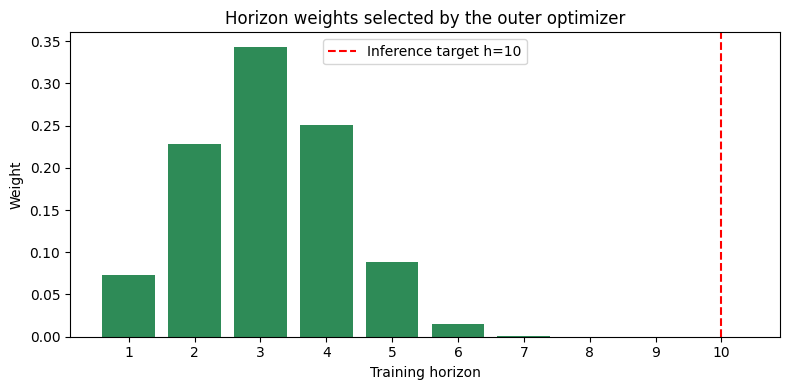

In [32]:
plt.figure(figsize=(8, 4))

plt.bar(
    horizons,
    bilevel_weights,
    color="seagreen",
)

plt.axvline(
    target_horizon,
    color="red",
    linestyle="--",
    label="Inference target h=10",
)

plt.title("Horizon weights selected by the outer optimizer")
plt.xlabel("Training horizon")
plt.ylabel("Weight")
plt.xticks(horizons)
plt.legend()

plt.tight_layout()
plt.show()

## 7. Final test comparison

We now refit each method using the train and validation periods together. The test period has not been used for horizon selection.

In [33]:
development_mask = train_mask | validation_mask


def test_weights(weights, seed=random_seed):
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()

    all_targets = data[target_columns].to_numpy()
    training_target = all_targets @ weights

    model = make_model(seed)

    model.fit(
        data.loc[development_mask, feature_columns],
        training_target[development_mask],
    )

    predictions = model.predict(
        data.loc[test_mask, feature_columns]
    )

    y_true = data.loc[test_mask, "return_h10"]
    dates = data.loc[test_mask, "date"]

    pearson_ic = mean_daily_ic(
        y_true,
        predictions,
        dates,
    )

    rank_ic = mean_daily_rank_ic(
        y_true,
        predictions,
        dates,
    )

    return pearson_ic, rank_ic, predictions

In [34]:
selected_horizon = int(horizons[np.argmax(bilevel_weights)])
selected_horizon_weights = np.zeros(n_horizons)
selected_horizon_weights[selected_horizon - 1] = 1

top3_indices = np.argsort(bilevel_weights)[-3:]
top3_horizons = [int(h) for h in horizons[top3_indices][::-1]]
top3_equal_weights = np.zeros(n_horizons)
top3_equal_weights[top3_indices] = 1 / len(top3_indices)

# Final methods: direct target, learned mixture, single selected horizon,
# and the Appendix E.2-style average of the three largest-lambda labels.
methods = {
    "Direct target h=10": direct_weights,
    "Weighted mixture": bilevel_weights,
    f"Bilevel-selected h={selected_horizon} (retrained)": selected_horizon_weights,
    f"Top-3 selected average h={list(top3_horizons)}": top3_equal_weights,
}

print(f"Fixed entropy gamma: {entropy_gamma:.4f}")
print(f"Selected horizon from argmax(lambda): h={selected_horizon}")
print(f"Top-3 horizons from lambda: {list(top3_horizons)}")
print(f"Best fixed horizon by validation Pearson IC: h={best_fixed_horizon}")

Fixed entropy gamma: 0.0050
Selected horizon from argmax(lambda): h=3
Top-3 horizons from lambda: [3, 4, 2]
Best fixed horizon by validation Pearson IC: h=4


In [35]:
final_results = []
test_predictions = {}

for method, weights in methods.items():
    validation_ic, validation_rank_ic = validation_scores(weights)
    test_ic, test_rank_ic, predictions = test_weights(weights)

    test_predictions[method] = predictions

    final_results.append(
        {
            "Method": method,
            "Validation IC (Pearson)": validation_ic,
            "Validation Rank IC (Spearman)": validation_rank_ic,
            "Test IC (Pearson)": test_ic,
            "Test Rank IC (Spearman)": test_rank_ic,
        }
    )

final_results = pd.DataFrame(final_results)
final_results = final_results.sort_values(
    "Test IC (Pearson)",
    ascending=False,
).reset_index(drop=True)

# A DataFrame as the final expression is rendered as a table in Jupyter.
final_results.round(4)

,Method,Validation IC (Pearson),Validation Rank IC (Spearman),Test IC (Pearson),Test Rank IC (Spearman)
0,Bilevel-selected h=3 (retrained),0.2738,0.2648,0.3897,0.3577
1,Weighted mixture,0.2813,0.2715,0.3887,0.3572
2,"Top-3 selected average h=[3, 4, 2]",0.2781,0.2692,0.3866,0.3574
3,Direct target h=10,0.2360,0.2374,0.3782,0.3446


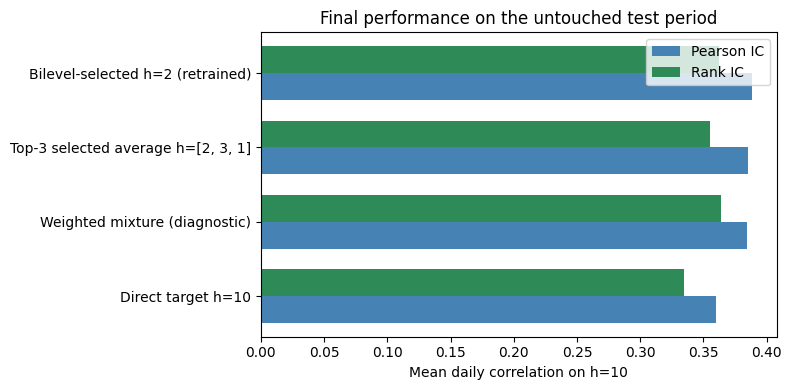

In [31]:
plt.figure(figsize=(8, 4))

plot_results = final_results.sort_values("Test IC (Pearson)")
positions = np.arange(len(plot_results))
bar_height = 0.36

plt.barh(
    positions - bar_height / 2,
    plot_results["Test IC (Pearson)"],
    height=bar_height,
    color="steelblue",
    label="Pearson IC",
)

plt.barh(
    positions + bar_height / 2,
    plot_results["Test Rank IC (Spearman)"],
    height=bar_height,
    color="seagreen",
    label="Rank IC",
)

plt.yticks(positions, plot_results["Method"])
plt.title("Final performance on the untouched test period")
plt.xlabel("Mean daily correlation on h=10")
plt.legend()

plt.tight_layout()
plt.show()

## 8. Conclusion

In this example:

- The prediction goal remained the return at `h=10`.
- Training directly on `h=10` was not the best approach.
- The fixed-horizon experiment showed that earlier labels worked better.
- The Optuna outer loop learned a distribution over candidate horizons using the fixed entropy strength `gamma=0.005`.
- Following the paper, the final horizon was selected using `argmax(lambda)` and a fresh LightGBM was retrained using only that horizon.
- Following Appendix E.2, the three largest-weight horizons were also combined through an equal arithmetic mean of their standardized labels.
- The weighted-label mixture is retained only as a diagnostic comparison, not as the paper-style final model.
- The selected-horizon retrain improved both test Pearson IC and test Rank IC relative to the direct-target baseline.

The result does not mean that an earlier horizon will always be better. It gives us a leakage-aware procedure for testing whether the training target should differ from the inference target.

### Main difference from the paper

The paper differentiates through a neural-network training step. Here, LightGBM is treated as a black box:

```text
Optuna chooses horizon weights lambda
            ↓
LightGBM fits the weighted target
            ↓
validation Pearson IC is calculated on h=10
            ↓
Optuna proposes new weights
            ↓
select h* = argmax(lambda) and retrain LightGBM on h*
```

## 9. Using the code on a real dataset

The real dataframe should contain:

- one row per asset and date;
- feature columns;
- one training label for each candidate horizon;
- the fixed final return used for validation and testing.